In [ ]:
#google drive a bağlanma
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


📥 Ses dosyaları işleniyor...

  Bulunan  : 360
  İşlenen  : 360
  Öznitelik: 422

  Eğitim: 288 | Test: 72

═══════════════════════════════════════════════════════
  ▶  AŞAMA 1: TONE
═══════════════════════════════════════════════════════
  🔁 TONE ADASYN: 288 → 288
  🔍 TONE CV: 0.736  (PCA=0.85, smooth=1.5e-02)
  🎯 TONE Kalibrasyon: isotonic

  📈 TONE Balanced Accuracy: 83.3%
              precision    recall  f1-score   support

   aggresive       0.77      0.71      0.74        24
       happy       0.90      0.79      0.84        24
     neutral       0.83      1.00      0.91        24

    accuracy                           0.83        72
   macro avg       0.84      0.83      0.83        72
weighted avg       0.84      0.83      0.83        72



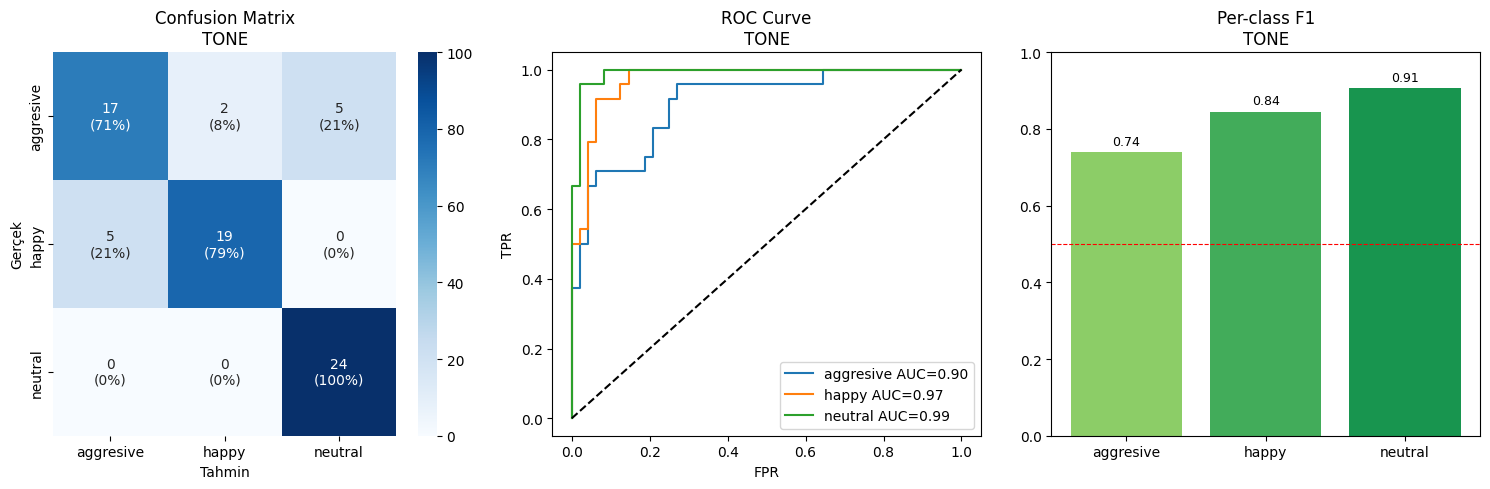


═══════════════════════════════════════════════════════
  ▶  AŞAMA 2: CONTENT  (tone-augmented öznitelikler)
═══════════════════════════════════════════════════════
  🔁  SMOTE : 230 → 231
  🔍  CV: 0.706  (PCA=0.85, smooth=1.0e-01)
  🎯  Kalibrasyon: isotonic
  🔁  SMOTE : 230 → 231
  🔍  CV: 0.702  (PCA=0.97, smooth=3.2e-04)
  🎯  Kalibrasyon: isotonic
  🔁  SMOTE : 230 → 231
  🔍  CV: 0.759  (PCA=0.92, smooth=2.2e-03)
  🎯  Kalibrasyon: isotonic
  🔁  ADASYN: 231 → 231
  🔍  CV: 0.762  (PCA=0.85, smooth=3.2e-04)
  🎯  Kalibrasyon: isotonic
  🔁  ADASYN: 231 → 231
  🔍  CV: 0.736  (PCA=0.85, smooth=1.5e-02)
  🎯  Kalibrasyon: isotonic
  Öznitelik boyutu: 422 → 425 (+3 tone olasılığı)

  🔁 CONTENT SMOTE : 288 → 297
  🔍 CONTENT CV: 0.495  (PCA=0.97, smooth=1.0e-11)
  🎯 CONTENT Kalibrasyon: isotonic

  📈 CONTENT Balanced Accuracy (ham): 55.0%
              precision    recall  f1-score   support

     hateful       0.55      0.75      0.63        24
     neutral       0.47      0.38      0.42        

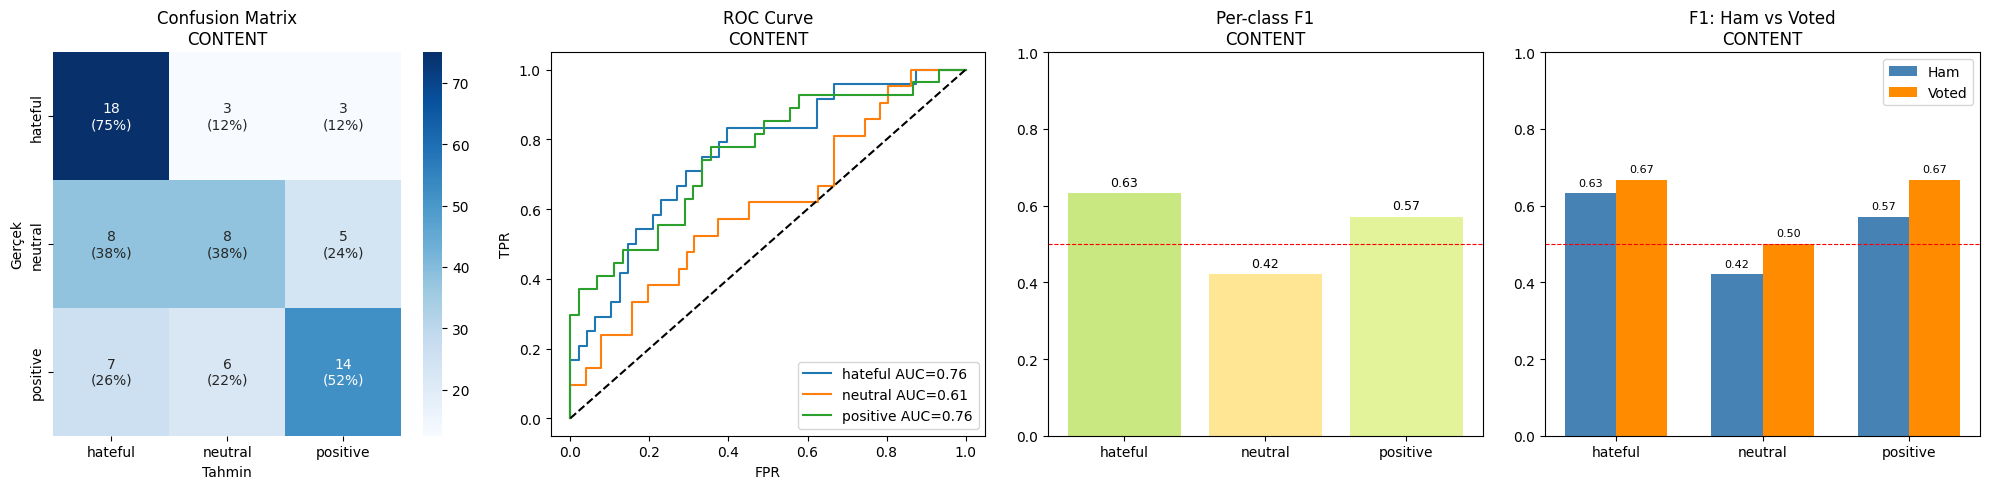


═══════════════════════════════════════════════════════
  TONE    : 83.3%
  CONTENT : 55.0%  →  61.5% (voted)
═══════════════════════════════════════════════════════
  💾 nb_toneaware_bundle.pkl


In [ ]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB, ComplementNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import (
    LabelEncoder, StandardScaler, MinMaxScaler, label_binarize
)
from sklearn.model_selection import (
    GroupShuffleSplit, StratifiedKFold, GridSearchCV
)
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, balanced_accuracy_score, f1_score
)
from sklearn.decomposition import PCA
from sklearn.feature_selection import (
    SelectKBest, mutual_info_classif, VarianceThreshold
)
from sklearn.pipeline import Pipeline
from collections import Counter

warnings.filterwarnings("ignore")

try:
    from imblearn.over_sampling import SMOTE, ADASYN
    SMOTE_AVAILABLE = True
except ImportError:
    SMOTE_AVAILABLE = False
    print("⚠️  pip install imbalanced-learn\n")


# ================================================================
# 1. ÖZNİTELİK ÇIKARIMI
# ================================================================
def extract_features(y, sr):
    try:
        y, _ = librosa.effects.trim(y, top_db=20)
        y = librosa.util.normalize(y)
        feats = []

        rms = librosa.feature.rms(y=y).ravel()
        feats += [rms.mean(), rms.std()]

        zcr = librosa.feature.zero_crossing_rate(y).ravel()
        feats += [zcr.mean(), zcr.std()]

        onset_env = librosa.onset.onset_strength(y=y, sr=sr)
        tempo = librosa.beat.tempo(onset_envelope=onset_env, sr=sr)[0]
        feats += [float(tempo)]

        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
        d1   = librosa.feature.delta(mfcc)
        d2   = librosa.feature.delta(mfcc, order=2)
        for mat in [mfcc, d1, d2]:
            feats += list(mat.mean(axis=1)) + list(mat.std(axis=1))

        for fn in [librosa.feature.spectral_centroid,
                   librosa.feature.spectral_bandwidth,
                   librosa.feature.spectral_rolloff]:
            v = fn(y=y, sr=sr).ravel()
            feats += [v.mean(), v.std()]

        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        feats += list(contrast.mean(axis=1)) + list(contrast.std(axis=1))

        flatness = librosa.feature.spectral_flatness(y=y).ravel()
        feats += [flatness.mean(), flatness.std()]

        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        feats += list(chroma.mean(axis=1)) + list(chroma.std(axis=1))

        mel    = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
        mel_db = librosa.power_to_db(mel)
        feats += list(mel_db.mean(axis=1)) + list(mel_db.std(axis=1))

        f0, _, _ = librosa.pyin(y,
                                 fmin=librosa.note_to_hz('C2'),
                                 fmax=librosa.note_to_hz('C7'))
        f0v = f0[~np.isnan(f0)] if f0 is not None else np.array([0.])
        if len(f0v) == 0:
            f0v = np.array([0.])
        feats += [f0v.mean(), f0v.std(), float(f0v.max() - f0v.min())]

        return np.array(feats, dtype=np.float32)

    except Exception as e:
        print(f"  ❌ {e}")
        return None


# ================================================================
# 2. VERİ HAZIRLAMA
# ================================================================
def prepare_dataset(csv_path, audio_dir):
    df = pd.read_csv(csv_path)
    X, y_tone, y_content, sent_ids = [], [], [], []
    found = 0

    print("📥 Ses dosyaları işleniyor...\n")
    for _, row in df.iterrows():
        path = os.path.join(audio_dir, row["name"])
        if not os.path.exists(path):
            continue
        found += 1
        try:
            y, sr = librosa.load(path, sr=22050)
            feats = extract_features(y, sr)
            if feats is not None:
                X.append(feats)
                y_tone.append(row["tone"])
                y_content.append(row["content"])
                sent_ids.append(row["sentence_id"])
        except Exception as e:
            print(f"  Hata ({row['name']}): {e}")

    X = np.array(X)
    print(f"{'='*55}")
    print(f"  Bulunan  : {found}")
    print(f"  İşlenen  : {len(X)}")
    print(f"  Öznitelik: {X.shape[1] if len(X) else '—'}")
    print(f"{'='*55}\n")
    return X, np.array(y_tone), np.array(y_content), np.array(sent_ids)


# ================================================================
# 3. OVERSAMPLING
# ================================================================
def oversample(X, y, label=""):
    if not SMOTE_AVAILABLE:
        return X, y
    counts = np.bincount(y)
    min_c  = counts.min()
    if min_c < 2:
        print(f"  ⚠️  {label}: Oversampling atlandı (yetersiz örnek).")
        return X, y
    k = min(5, min_c - 1)
    try:
        X_r, y_r = ADASYN(random_state=42, n_neighbors=k).fit_resample(X, y)
        print(f"  🔁 {label} ADASYN: {len(X)} → {len(X_r)}")
    except Exception:
        X_r, y_r = SMOTE(random_state=42, k_neighbors=k).fit_resample(X, y)
        print(f"  🔁 {label} SMOTE : {len(X)} → {len(X_r)}")
    return X_r, y_r


# ================================================================
# 4. NB MODELİ KURMA (Pipeline + GridSearch + Kalibrasyon)
# ================================================================
def build_model(X_train, y_train, label=""):
    n_samples = len(X_train)

    pipe = Pipeline([
        ("var",    VarianceThreshold(threshold=1e-5)),
        ("scaler", StandardScaler()),
        ("pca",    PCA(random_state=42)),
        ("select", SelectKBest(mutual_info_classif)),
        ("nb",     GaussianNB()),
    ])

    param_grid = {
        "pca__n_components": [0.85, 0.92, 0.97],
        "select__k":         ["all"],
        "nb__var_smoothing": np.logspace(-11, -1, 13),
    }

    n_splits = max(2, min(5, int(np.bincount(y_train).min())))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    gs = GridSearchCV(pipe, param_grid, cv=cv,
                      scoring="balanced_accuracy",
                      n_jobs=-1, refit=True, verbose=0)
    try:
        gs.fit(X_train, y_train)
        bp = gs.best_params_
        print(f"  🔍 {label} CV: {gs.best_score_:.3f}  "
              f"(PCA={bp['pca__n_components']}, "
              f"smooth={bp['nb__var_smoothing']:.1e})")
        best_pipe = gs.best_estimator_
    except Exception as e:
        print(f"  ⚠️  GridSearch hatası: {e} → varsayılan GaussianNB")
        best_pipe = pipe
        best_pipe.set_params(pca__n_components=0.95,
                             nb__var_smoothing=1e-9)
        best_pipe.fit(X_train, y_train)

    cal_method = "sigmoid" if n_samples < 150 else "isotonic"
    calibrated = CalibratedClassifierCV(best_pipe, cv=cv, method=cal_method)
    calibrated.fit(X_train, y_train)
    print(f"  🎯 {label} Kalibrasyon: {cal_method}")
    return calibrated


# ================================================================
# 5. CÜMLE BAZLI OYLAMA (Majority Voting)
# ================================================================
def sentence_voting(y_pred, sent_ids_test, n_classes):
    """
    Aynı sentence_id için birden fazla ses varsa
    (aynı cümlenin farklı ton versiyonları),
    majority vote ile tek tahmin üret.
    """
    # Her unique (sentence_id) için tahminleri topla
    groups = {}
    for idx, (sid, pred) in enumerate(zip(sent_ids_test, y_pred)):
        groups.setdefault(sid, []).append((idx, pred))

    y_voted = y_pred.copy()
    n_voted = 0
    for sid, items in groups.items():
        if len(items) > 1:
            indices = [i for i, _ in items]
            preds   = [p for _, p in items]
            majority = Counter(preds).most_common(1)[0][0]
            for i in indices:
                y_voted[i] = majority
            n_voted += len(items)

    print(f"  🗳️  Oylama uygulanan örnek: {n_voted}/{len(y_pred)}")
    return y_voted


# ================================================================
# 6. GÖRSELLEŞTİRME
# ================================================================
def plot_results(y_true, y_pred, y_score, classes, title,
                 y_pred_voted=None):
    n = len(classes)
    ncols = 4 if y_pred_voted is not None else 3
    fig, axes = plt.subplots(1, ncols, figsize=(5*ncols, 5))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{cm[i,j]}\n({cm_pct[i,j]:.0f}%)"
                       for j in range(n)] for i in range(n)])
    sns.heatmap(cm_pct, annot=annot, fmt="", cmap="Blues",
                xticklabels=classes, yticklabels=classes, ax=axes[0])
    axes[0].set_title(f"Confusion Matrix\n{title}")
    axes[0].set_xlabel("Tahmin"); axes[0].set_ylabel("Gerçek")

    # ROC
    if n == 2:
        fpr, tpr, _ = roc_curve(y_true, y_score[:, 1])
        axes[1].plot(fpr, tpr, label=f"AUC={auc(fpr,tpr):.2f}")
    else:
        y_bin = label_binarize(y_true, classes=range(n))
        for i in range(n):
            fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
            axes[1].plot(fpr, tpr,
                         label=f"{classes[i]} AUC={auc(fpr,tpr):.2f}")
    axes[1].plot([0,1],[0,1],"k--")
    axes[1].set_title(f"ROC Curve\n{title}")
    axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
    axes[1].legend(loc="lower right")

    # Per-class F1
    f1s = f1_score(y_true, y_pred, average=None, zero_division=0)
    colors = plt.cm.RdYlGn(f1s)
    axes[2].bar(classes, f1s, color=colors)
    axes[2].set_ylim(0, 1)
    axes[2].axhline(0.5, color="red", linestyle="--", lw=0.8)
    axes[2].set_title(f"Per-class F1\n{title}")
    for i, v in enumerate(f1s):
        axes[2].text(i, v+0.02, f"{v:.2f}", ha="center", fontsize=9)

    # Voting karşılaştırması
    if y_pred_voted is not None:
        f1s_v = f1_score(y_true, y_pred_voted, average=None, zero_division=0)
        x = np.arange(n)
        w = 0.35
        axes[3].bar(x - w/2, f1s,   w, label="Ham",   color="steelblue")
        axes[3].bar(x + w/2, f1s_v, w, label="Voted", color="darkorange")
        axes[3].set_xticks(x); axes[3].set_xticklabels(classes)
        axes[3].set_ylim(0, 1)
        axes[3].axhline(0.5, color="red", linestyle="--", lw=0.8)
        axes[3].set_title(f"F1: Ham vs Voted\n{title}")
        axes[3].legend()
        for i, (v1, v2) in enumerate(zip(f1s, f1s_v)):
            axes[3].text(i-w/2, v1+0.02, f"{v1:.2f}", ha="center", fontsize=8)
            axes[3].text(i+w/2, v2+0.02, f"{v2:.2f}", ha="center", fontsize=8)

    plt.tight_layout()
    plt.show()


# ================================================================
# 7. ANA EĞİTİM
# ================================================================
def train(csv_path, audio_dir):
    X, y_t, y_c, ids = prepare_dataset(csv_path, audio_dir)
    if len(X) == 0:
        print("❌ Veri bulunamadı!"); return

    le_t = LabelEncoder(); y_t_enc = le_t.fit_transform(y_t)
    le_c = LabelEncoder(); y_c_enc = le_c.fit_transform(y_c)

    # Grup bazlı bölünme — aynı sentence_id test+train'e bölünmesin
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr, te = next(gss.split(X, y_c_enc, groups=ids))

    X_tr, X_te         = X[tr], X[te]
    y_t_tr, y_t_te     = y_t_enc[tr], y_t_enc[te]
    y_c_tr, y_c_te     = y_c_enc[tr], y_c_enc[te]
    ids_tr, ids_te     = ids[tr], ids[te]

    print(f"  Eğitim: {len(X_tr)} | Test: {len(X_te)}\n")

    # ── AŞAMA 1: TONE MODELİ ────────────────────────────────
    print(f"{'═'*55}\n  ▶  AŞAMA 1: TONE\n{'═'*55}")
    X_t_os, y_t_os = oversample(X_tr, y_t_tr, "TONE")
    tone_model = build_model(X_t_os, y_t_os, "TONE")

    t_pred  = tone_model.predict(X_te)
    t_score = tone_model.predict_proba(X_te)

    t_bal = balanced_accuracy_score(y_t_te, t_pred)
    print(f"\n  📈 TONE Balanced Accuracy: {t_bal*100:.1f}%")
    print(classification_report(y_t_te, t_pred,
                                  target_names=le_t.classes_,
                                  zero_division=0))
    plot_results(y_t_te, t_pred, t_score, le_t.classes_, "TONE")

    # ── AŞAMA 2: CONTENT — Tone Olasılıkları Ekleniyor ──────
    print(f"\n{'═'*55}")
    print(f"  ▶  AŞAMA 2: CONTENT  (tone-augmented öznitelikler)")
    print(f"{'═'*55}")

    # Eğitim setinde tone olasılıkları: in-fold tahmin (veri sızıntısı önlemi)
    # StratifiedKFold ile her fold'un out-of-fold tone_proba'sını kullan
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    tone_proba_tr = np.zeros((len(X_tr), len(le_t.classes_)))

    for fold_tr, fold_val in skf.split(X_tr, y_t_tr):
        X_f_tr, X_f_val = X_tr[fold_tr], X_tr[fold_val]
        y_f_tr          = y_t_tr[fold_tr]
        X_f_os, y_f_os  = oversample(X_f_tr, y_f_tr)
        fold_tone = build_model(X_f_os, y_f_os)
        tone_proba_tr[fold_val] = fold_tone.predict_proba(X_f_val)

    # Test için nihai tone modelinin olasılıklarını kullan
    tone_proba_te = t_score  # zaten tone_model.predict_proba(X_te)

    # Birleştir: [ses_özellikleri | tone_olasılıkları]
    X_tr_aug = np.hstack([X_tr, tone_proba_tr])
    X_te_aug = np.hstack([X_te, tone_proba_te])

    print(f"  Öznitelik boyutu: {X_tr.shape[1]} → {X_tr_aug.shape[1]} "
          f"(+{len(le_t.classes_)} tone olasılığı)\n")

    X_c_os, y_c_os = oversample(X_tr_aug, y_c_tr, "CONTENT")
    cont_model = build_model(X_c_os, y_c_os, "CONTENT")

    c_pred  = cont_model.predict(X_te_aug)
    c_score = cont_model.predict_proba(X_te_aug)

    c_bal = balanced_accuracy_score(y_c_te, c_pred)
    print(f"\n  📈 CONTENT Balanced Accuracy (ham): {c_bal*100:.1f}%")
    print(classification_report(y_c_te, c_pred,
                                  target_names=le_c.classes_,
                                  zero_division=0))

    # ── AŞAMA 3: CÜMLE BAZLI OYLAMA ─────────────────────────
    print(f"\n{'═'*55}")
    print(f"  ▶  AŞAMA 3: Cümle Bazlı Oylama")
    print(f"{'═'*55}")

    c_pred_voted = sentence_voting(c_pred, ids_te, len(le_c.classes_))
    c_bal_voted  = balanced_accuracy_score(y_c_te, c_pred_voted)
    print(f"\n  📈 CONTENT Balanced Accuracy (voted): {c_bal_voted*100:.1f}%")
    print(classification_report(y_c_te, c_pred_voted,
                                  target_names=le_c.classes_,
                                  zero_division=0))

    plot_results(y_c_te, c_pred, c_score, le_c.classes_, "CONTENT",
                 y_pred_voted=c_pred_voted)

    # ── ÖZET ────────────────────────────────────────────────
    print(f"\n{'═'*55}")
    print(f"  TONE    : {t_bal*100:.1f}%")
    print(f"  CONTENT : {c_bal*100:.1f}%  →  {c_bal_voted*100:.1f}% (voted)")
    print(f"{'═'*55}")

    # Kaydet
    joblib.dump({
        "tone_model": tone_model,
        "cont_model": cont_model,
        "le_tone":    le_t,
        "le_content": le_c,
    }, "nb_toneaware_bundle.pkl")
    print("  💾 nb_toneaware_bundle.pkl")


# ================================================================
# 8. TAHMİN
# ================================================================
def predict_audio(audio_path, bundle_path="nb_toneaware_bundle.pkl"):
    b = joblib.load(bundle_path)
    y, sr = librosa.load(audio_path, sr=22050)
    f = extract_features(y, sr)
    if f is None:
        return None, None

    X = f.reshape(1, -1)

    # Tone tahmini
    tone_proba = b["tone_model"].predict_proba(X)
    tone_label = b["le_tone"].inverse_transform(
                     b["tone_model"].predict(X))[0]

    # Content tahmini (ses + tone olasılığı)
    X_aug = np.hstack([X, tone_proba])
    cont_label = b["le_content"].inverse_transform(
                     b["cont_model"].predict(X_aug))[0]

    print(f"🎤 Tone: {tone_label}  |  Content: {cont_label}")
    return tone_label, cont_label


if __name__ == "__main__":
    CSV_PATH  = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/labels.csv"
    AUDIO_DIR = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/sesler"
    train(CSV_PATH, AUDIO_DIR)